# Day 45: Sales & Service Demand Forecasting System

**Dataset:** a simulated three-year history of the daily demand for the four service lines of Veda
Technology (October 1, 2023 to September 30, 2026)

This notebook is the first of four days in the Sales & Service Demand Forecasting System project.
It creates the historical service-demand dataset, builds a time-series preprocessing pipeline, and
visualizes the monthly and weekly demand. Day 46 analyzes trend and seasonality and builds a
baseline forecast, Day 47 builds and evaluates the forecasting model, and Day 48 builds the future
demand dashboard and the business planning recommendations.

## 1. Import Libraries

In [1]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Folders
DATA_DIR = Path("../datasets/veda_demand")
for sub in ("raw", "cleaned", "reference"):
    (DATA_DIR / sub).mkdir(parents=True, exist_ok=True)

SEED = 42
START, END = pd.Timestamp("2023-10-01"), pd.Timestamp("2026-09-30")
LINES = ["Internship Programs", "Training Programs", "IT Services", "Digital Services"]
# One fixed color per service line (the first four slots of a validated categorical palette, in order)
COLORS = {"Internship Programs": "#2a78d6", "Training Programs": "#eb6834", "IT Services": "#1baf7a", "Digital Services": "#eda100"}
INK, INK_SOFT, GRID, SURFACE = "#0b0b0b", "#52514e", "#dcdad4", "#fcfcfb"
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT, "xtick.color": INK_SOFT,
                     "ytick.color": INK_SOFT, "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "figure.facecolor": SURFACE, "axes.facecolor": SURFACE})


def clean_axes(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.7)
    ax.set_axisbelow(True)

## 2. The Historical Service-Demand Dataset

**Why a simulated dataset**

The project hint says to use synthetic historical data, and Veda Technology's real records are
private. The dataset is generated with a fixed random seed so that anyone can reproduce it. The
first project (Days 35 to 38) had only one year of history, which is not enough to separate
growth from seasonality, so this dataset covers **three years** (36 months, 1,096 days).

**What the data records**

One row per day and service line: the demand (applications, enrollments, or inquiries), the
revenue it brought in, and whether a marketing campaign was running. The four service lines are the
same as in the earlier projects: Internship Programs, Training Programs, IT Services, and Digital
Services. The volumes of the final year are set close to those of the Day 35 dataset.

**What is built into the simulation** (none of this is saved in the data, so the next days have to find it)

- a **growth trend** that differs by line (the fastest for Digital Services, the slowest for Internship Programs);
- a **yearly seasonality** that differs by line (internships peak in January and June, training in July, IT services in March, digital services in July and November);
- a **weekly pattern** (more demand on weekdays than on weekends, and IT services drop the most on weekends);
- **public holidays** with lower demand, and **marketing campaigns** that lift demand by about 30% for about two weeks;
- random day-to-day noise (more than a simple count would have);
- a **change in the last months**: a new bundle that lifts Digital Services from June 2026, and a slowdown of IT Services from July 2026. This is there so that the forecasting days can show why historical trends do not always predict future demand.

In [2]:
rng = np.random.default_rng(SEED)
dates = pd.date_range(START, END, freq="D")
n_days = len(dates)
years_since_start = (dates - START).days.to_numpy() / 365.25

# ---- public holidays (a reference table, saved for the forecasting days) ----
fixed = {"01-01": "New Year's Day", "05-01": "Labor Day", "06-12": "Independence Day", "11-01": "All Saints' Day",
         "11-30": "Bonifacio Day", "12-24": "Christmas Eve", "12-25": "Christmas Day", "12-30": "Rizal Day", "12-31": "New Year's Eve"}
holiday_rows = [(d, fixed[d.strftime("%m-%d")]) for d in dates if d.strftime("%m-%d") in fixed]
holiday_rows += [(pd.Timestamp(d), name) for d, name in [("2024-03-28", "Holy Thursday"), ("2024-03-29", "Good Friday"),
                                                         ("2025-04-17", "Holy Thursday"), ("2025-04-18", "Good Friday"),
                                                         ("2026-04-02", "Holy Thursday"), ("2026-04-03", "Good Friday")]]
holidays = pd.DataFrame(holiday_rows, columns=["date", "holiday"]).sort_values("date").reset_index(drop=True)
holidays.to_csv(DATA_DIR / "reference" / "holiday_calendar.csv", index=False)
is_holiday = dates.isin(holidays["date"])

# ---- the building blocks of the demand of each line ----
month_profile = {   # relative demand for January to December
    "Internship Programs": [1.30, 1.20, 0.95, 0.85, 0.95, 1.25, 1.00, 0.85, 0.80, 0.90, 0.95, 1.00],
    "Training Programs":   [1.15, 0.95, 0.85, 0.80, 0.90, 1.10, 1.45, 1.05, 0.85, 0.90, 0.95, 0.75],
    "IT Services":         [0.90, 1.00, 1.30, 1.00, 0.95, 0.90, 0.95, 0.90, 1.05, 1.10, 0.95, 0.70],
    "Digital Services":    [0.85, 0.85, 0.90, 0.95, 1.00, 1.05, 1.25, 1.05, 0.95, 1.00, 1.10, 1.00]}
weekday_profile = {   # relative demand for Monday to Sunday
    "Internship Programs": [1.20, 1.20, 1.15, 1.10, 1.00, 0.65, 0.45],
    "Training Programs":   [1.15, 1.20, 1.20, 1.10, 1.00, 0.80, 0.55],
    "IT Services":         [1.30, 1.30, 1.25, 1.15, 1.05, 0.40, 0.25],
    "Digital Services":    [1.20, 1.25, 1.20, 1.15, 1.00, 0.60, 0.40]}
yearly_growth = {"Internship Programs": 0.10, "Training Programs": 0.14, "IT Services": 0.16, "Digital Services": 0.24}
final_year_units_per_day = {"Internship Programs": 2600 / 365, "Training Programs": 1800 / 365, "IT Services": 1100 / 365, "Digital Services": 1300 / 365}
revenue_per_unit = {"Internship Programs": (1200, 0.3), "Training Programs": (13400, 0.4), "IT Services": (85000, 0.9), "Digital Services": (12000, 0.7)}

month_position = np.array([d.month - 1 + (d.day - 1) / d.days_in_month for d in dates])   # 0 to 12


def smooth_monthly(profile):
    values = np.array(profile) / np.mean(profile)
    anchors = np.arange(12) + 0.5
    return np.interp(month_position, np.concatenate([anchors - 12, anchors, anchors + 12]), np.tile(values, 3))


final_year = (dates >= "2025-10-01")
ramp = lambda start, days: np.clip((dates - pd.Timestamp(start)).days.to_numpy() / days, 0, 1)
regime = {"Internship Programs": np.ones(n_days), "Training Programs": np.ones(n_days),
          "IT Services": 1 - 0.18 * ramp("2026-07-01", 14), "Digital Services": 1 + 0.35 * ramp("2026-06-01", 14)}

records = []
for line in LINES:
    weekday = np.array(weekday_profile[line])
    weekday = (weekday / weekday.mean())[dates.dayofweek]
    # marketing campaigns: in about 55% of the months, one campaign of 10 to 14 days
    campaign = np.zeros(n_days, dtype=int)
    for month_start in pd.date_range(START, END, freq="MS"):
        if rng.random() < 0.55:
            first = (month_start - START).days + int(rng.integers(0, 18))
            campaign[first: first + int(rng.integers(10, 15))] = 1
    shape = (np.exp(yearly_growth[line] * years_since_start) * smooth_monthly(month_profile[line]) * weekday
             * np.where(is_holiday, 0.5, 1.0) * (1 + 0.30 * campaign))
    base = final_year_units_per_day[line] / shape[final_year].mean()          # calibrates the volume of the final year
    expected = base * shape * regime[line]
    units = rng.poisson(rng.gamma(shape=12, scale=expected / 12))               # a count that varies more than a Poisson count
    avg_value, spread = revenue_per_unit[line]
    noise = np.exp(rng.normal(0, spread / np.sqrt(np.maximum(units, 1)), n_days) - spread ** 2 / (2 * np.maximum(units, 1)))
    revenue = np.where(units > 0, np.round(units * avg_value * noise, -2), 0)
    records.append(pd.DataFrame({"date": dates, "service_line": line, "demand_units": units, "revenue_inr": revenue, "campaign_active": campaign}))

truth = pd.concat(records, ignore_index=True)      # the clean original, kept only to check the pipeline later
print("Clean original:", truth.shape, "| days:", n_days, "| lines:", truth["service_line"].nunique())
print("Units in the final year:", truth.loc[truth["date"] >= "2025-10-01"].groupby("service_line")["demand_units"].sum().reindex(LINES).to_dict())

Clean original: (4384, 5) | days: 1096 | lines: 4
Units in the final year: {'Internship Programs': 2605, 'Training Programs': 1864, 'IT Services': 1001, 'Digital Services': 1411}


**Making the data realistic: a deliberately messy raw export**

Real demand exports are never clean, so the clean table is damaged in the ways that time-series
data usually is, and the preprocessing pipeline has to repair it:

- some **days are missing** (a few single rows, and five days in February 2025 when all four lines are absent during a "system migration");
- a **system outage** in January 2025 records **zero** demand for six days for IT Services;
- a few **spikes** where an extra zero was typed (a value ten times too large);
- **impossible values** (negative demand), and **empty cells**;
- **numbers typed as text** (`14 units`, `₹12,500`, `Rs. 12,500`, `12500 INR`);
- **inconsistent service line names** (`it services`, `Digital`, `Internships`), and **two date formats** (`2024-10-05` and `05-Oct-2024`);
- a campaign flag typed in several ways (`1`, `Yes`, `Y`, `TRUE`, ...), and **duplicate rows** (exact copies, and days exported twice with another spelling).

In [3]:
rng = np.random.default_rng(SEED + 1)
raw = truth.copy()
touched = {}      # which (date, line) rows were damaged, to evaluate the pipeline later


def keys(frame):
    return set(zip(frame["date"], frame["service_line"]))


# 1. five days missing for all lines (system migration), and 60 random missing rows
migration = pd.date_range("2025-02-10", periods=5)
touched["migration_missing"] = keys(raw[raw["date"].isin(migration)])
raw = raw[~raw["date"].isin(migration)]
dropped = rng.choice(raw.index, size=60, replace=False)
touched["random_missing"] = keys(raw.loc[dropped])
raw = raw.drop(dropped)

# 2. an outage: six days of zero demand for IT Services
outage = (raw["service_line"] == "IT Services") & raw["date"].isin(pd.date_range("2025-01-20", periods=6))
touched["outage_zero"] = keys(raw[outage])
raw.loc[outage, ["demand_units", "revenue_inr"]] = 0

# 3. spikes (an extra zero typed in the units), negative values, and empty cells
pool = raw.index.difference(raw.index[outage])
spike_rows = rng.choice(pool[raw.loc[pool, "demand_units"] >= 2], size=12, replace=False)
touched["spike"] = keys(raw.loc[spike_rows])
raw.loc[spike_rows, "demand_units"] = raw.loc[spike_rows, "demand_units"] * 10
pool = pool.difference(spike_rows)
negative_rows = rng.choice(pool, size=8, replace=False)
touched["negative"] = keys(raw.loc[negative_rows])
raw.loc[negative_rows, "demand_units"] = -raw.loc[negative_rows, "demand_units"].clip(lower=1)
pool = pool.difference(negative_rows)
units_empty = rng.choice(pool, size=50, replace=False)
touched["units_empty"] = keys(raw.loc[units_empty])
raw["demand_units"] = raw["demand_units"].astype(float)
raw.loc[units_empty, "demand_units"] = np.nan
raw["revenue_inr"] = raw["revenue_inr"].astype(float)
raw.loc[rng.choice(raw.index, size=40, replace=False), "revenue_inr"] = np.nan
raw["campaign_active"] = raw["campaign_active"].astype(float)
raw.loc[rng.choice(raw.index, size=30, replace=False), "campaign_active"] = np.nan

# 4. numbers typed as text
raw["demand_units"] = raw["demand_units"].map(lambda v: v if np.isnan(v) else int(v)).astype(object)
text_units = rng.choice(raw.index[raw["demand_units"].notna()], size=40, replace=False)
raw.loc[text_units, "demand_units"] = raw.loc[text_units, "demand_units"].map(lambda v: f"{v} units")
text_revenue = rng.choice(raw.index[raw["revenue_inr"].notna()], size=80, replace=False)
raw["revenue_inr"] = raw["revenue_inr"].astype(object)
raw.loc[text_revenue, "revenue_inr"] = [[f"\u20b9{v:,.0f}", f"Rs. {v:,.0f}", f"{v:.0f} INR"][rng.integers(3)] for v in raw.loc[text_revenue, "revenue_inr"].astype(float)]

# 5. inconsistent service line names and two date formats
aliases = {"Internship Programs": ["Internship Programs", "internship programs", "Internships", "Internship"],
           "Training Programs": ["Training Programs", "training programs", "Training", "Training Program "],
           "IT Services": ["IT Services", "it services", "IT Service", "IT"],
           "Digital Services": ["Digital Services", "digital services", "Digital", "DIGITAL SERVICES"]}
canonical_share = 0.6
raw["service_line"] = [aliases[line][0] if rng.random() < canonical_share else aliases[line][rng.integers(1, 4)] for line in raw["service_line"]]
use_text_date = rng.random(len(raw)) < 0.3
raw["date"] = np.where(use_text_date, raw["date"].dt.strftime("%d-%b-%Y"), raw["date"].dt.strftime("%Y-%m-%d"))

# 6. the campaign flag typed in several ways
yes, no = ["1", "Yes", "Y", "TRUE"], ["0", "No", "N", "FALSE"]
raw["campaign_active"] = [np.nan if np.isnan(v) else (yes if v == 1 else no)[rng.integers(4)] for v in raw["campaign_active"]]

# 7. duplicate rows: 50 exact copies, and 50 re-exported copies (another spelling of the service line)
exact = raw.loc[rng.choice(raw.index, size=50, replace=False)]
reexport = raw.loc[rng.choice(raw.index, size=50, replace=False)].copy()
reexport["service_line"] = [aliases[next(k for k, v in aliases.items() if s in v)][rng.integers(0, 4)] for s in reexport["service_line"]]
raw = pd.concat([raw, exact, reexport]).sort_index(kind="stable").reset_index(drop=True)

raw.to_csv(DATA_DIR / "raw" / "demand_raw.csv", index=False)
print("Raw file:", DATA_DIR / "raw" / "demand_raw.csv", "| rows:", len(raw), "(a complete history would have", n_days * 4, "rows)")
raw.head(8)

Raw file: ../datasets/veda_demand/raw/demand_raw.csv | rows: 4404 (a complete history would have 4384 rows)


,date,service_line,demand_units,revenue_inr,campaign_active
0,01-Oct-2023,Internship Programs,1.0,1200.0,0
1,02-Oct-2023,Internships,3.0,4400.0,FALSE
2,03-Oct-2023,Internship Programs,7.0,7800.0,FALSE
3,04-Oct-2023,Internship Programs,1.0,1000.0,0
4,2023-10-05,Internship,1.0,1100.0,N
5,2023-10-06,Internship Programs,0.0,0.0,N
6,07-Oct-2023,Internship Programs,6.0,6700.0,N
7,2023-10-08,Internship,2.0,2100.0,N


## 3. Inspect the Raw Data

Before cleaning anything, the raw file is read back exactly as an analyst would receive it
(everything as text) and checked for each of the problems above.

In [4]:
raw_table = pd.read_csv(DATA_DIR / "raw" / "demand_raw.csv", dtype=str)
print("Shape:", raw_table.shape)
print("Complete history would have:", n_days * 4, "rows | rows in the file:", len(raw_table))
print()
print("Empty cells per column:")
print(raw_table.isna().sum().to_string())
print()
print("Exact duplicate rows:", int(raw_table.duplicated().sum()))
print("Service line spellings:", raw_table["service_line"].nunique(), "->", sorted(raw_table["service_line"].unique()))
print("Date formats:", "ISO (2024-10-05):", int(raw_table["date"].str.match(r"^\d{4}-\d{2}-\d{2}$").sum()),
      "| day-month-year (05-Oct-2024):", int(raw_table["date"].str.match(r"^\d{2}-[A-Za-z]{3}-\d{4}$").sum()))
print("Demand typed as text:", int(raw_table["demand_units"].str.contains("units", na=False).sum()),
      "| revenue typed as text:", int(raw_table["revenue_inr"].str.contains(r"[^0-9.]", na=False).sum()))
print("Campaign flag spellings:", sorted(raw_table["campaign_active"].dropna().unique()))
raw_table.sample(6, random_state=1)

Shape: (4404, 5)
Complete history would have: 4384 rows | rows in the file: 4404

Empty cells per column:
date                0
service_line        0
demand_units       52
revenue_inr        40
campaign_active    31

Exact duplicate rows: 63
Service line spellings: 16 -> ['DIGITAL SERVICES', 'Digital', 'Digital Services', 'IT', 'IT Service', 'IT Services', 'Internship', 'Internship Programs', 'Internships', 'Training', 'Training Program ', 'Training Programs', 'digital services', 'internship programs', 'it services', 'training programs']
Date formats: ISO (2024-10-05): 3131 | day-month-year (05-Oct-2024): 1273
Demand typed as text: 40 | revenue typed as text: 81
Campaign flag spellings: ['0', '1', 'FALSE', 'N', 'No', 'TRUE', 'Y', 'Yes']


,date,service_line,demand_units,revenue_inr,campaign_active
1232,2024-02-11,training programs,NaN,39100.0,N
1020,2026-07-16,Internship Programs,12.0,13400.0,1
988,2026-06-15,Internship Programs,15.0,18800.0,No
3945,04-Jul-2025,digital services,2.0,14100.0,N
136,15-Feb-2024,internship programs,9.0,11300.0,FALSE
1475,2024-10-08,Training Programs,2.0,26800.0,No


**Observation:** The raw file has 4,404 rows, while a complete history of 1,096 days and four lines would have 4,384, so the file is both missing days and carrying extra rows. All the planned problems are present: 52 empty demand cells, 40 empty revenue cells, and 31 empty campaign flags; 63 exact duplicate rows; 16 different spellings for the four service lines; two date formats (3,131 rows in `2024-10-05` and 1,273 in `05-Oct-2024`); 40 demand values and 81 revenue values typed as text; and 8 spellings of a yes/no campaign flag. The checks above cannot see the five missing days of February 2025, the zero days of the IT outage, the spikes, or the negative values, because they hide inside values that look normal, which is why the pipeline has to look at the time series itself and not only at the cells.

## 4. Time-Series Preprocessing Pipeline

A time series has requirements that an ordinary table does not: every day must be present exactly
once for every line, and the order of the days matters, so a filled value has to respect the weekly
pattern. The pipeline is one function, driven by a short specification, with a log of what it
changed:

1. remove duplicate rows (exact copies, and the same day and line exported twice);
2. parse the two date formats and standardize the service line names;
3. convert the numbers typed as text, and standardize the campaign flag;
4. set impossible values (negative demand or revenue) to missing;
5. **rebuild the complete calendar** (one row per day and line), so missing days become visible;
6. detect an **outage** (five or more zero days in a row, which weekends and holidays alone do not produce) and set it to missing;
7. detect **spikes** (a value more than four times the typical value of the same weekday in the neighboring weeks, whose revenue does not agree with it) and set them to missing;
8. **fill** the missing demand: from the revenue when the revenue is known (demand = revenue divided by the usual revenue per unit), and otherwise with the median of the same weekday in the neighboring weeks (three weeks before and after); the missing revenue is the demand times the recent revenue per unit; and every filled value is flagged.

Filling with the same weekday keeps the weekly pattern, which a plain average or a straight line would
flatten. Every filled value is flagged, so the later models can see what is real and what is estimated.

In [5]:
SPEC = {
    "date_formats": ["%Y-%m-%d", "%d-%b-%Y"],
    "line_aliases": {alias.strip().lower(): line for line, names in aliases.items() for alias in names},
    "yes": {"1", "yes", "y", "true"}, "no": {"0", "no", "n", "false"},
    "start": START, "end": END,
    "outage_min_run": 5,                 # zero days in a row that count as an outage (weekends and holidays give shorter runs)
    "spike_ratio": 4, "spike_min_gap": 8,  # a spike is more than 4 times the weekday baseline and at least 8 units above it
    "spike_revenue_check": 0.5,            # ... and the revenue per unit is below half of the normal revenue per unit (the revenue does not agree)
    "neighbor_weeks": (1, 2, 3),
}


def weekday_baseline(values, weeks=(1, 2, 3)):
    """Median of the same weekday in the neighboring weeks (before and after), ignoring missing values."""
    out = np.full(len(values), np.nan)
    for i in range(len(values)):
        cand = [values[i + k * s] for k in weeks for s in (-7, 7) if 0 <= i + k * s < len(values) and not np.isnan(values[i + k * s])]
        if len(cand) >= 2:
            out[i] = np.median(cand)
    return out


def clean_demand(raw_text, spec):
    df = raw_text.copy()
    log = {"rows in the raw file": len(df)}

    # 1. exact duplicates
    before = len(df)
    df = df.drop_duplicates()
    log["exact duplicate rows removed"] = before - len(df)

    # 2. dates and service lines
    first_format = pd.to_datetime(df["date"], format=spec["date_formats"][0], errors="coerce")
    parsed = first_format.fillna(pd.to_datetime(df["date"], format=spec["date_formats"][1], errors="coerce"))
    assert parsed.notna().all(), "a date could not be parsed"
    log["dates in the second format converted"] = int(first_format.isna().sum())
    df["date"] = parsed
    standardized = df["service_line"].str.strip().str.lower().map(spec["line_aliases"])
    assert standardized.notna().all(), "an unknown service line"
    log["service line names standardized"] = int((standardized != raw_text.loc[df.index, "service_line"]).sum())
    df["service_line"] = standardized

    # 3. numbers typed as text and the campaign flag
    units = df["demand_units"].str.replace(r"(?i)\s*units?", "", regex=True).str.strip()
    revenue_text = df["revenue_inr"].str.replace(r"(?i)rs\.?|inr|₹|,|\s", "", regex=True)
    log["demand values typed as text converted"] = int(df["demand_units"].str.contains("units", na=False).sum())
    log["revenue values typed as text converted"] = int(df["revenue_inr"].str.contains(r"[^0-9.]", na=False).sum())
    df["demand_units"] = pd.to_numeric(units, errors="coerce").astype(float)
    df["revenue_inr"] = pd.to_numeric(revenue_text, errors="coerce").astype(float)
    flag = df["campaign_active"].str.strip().str.lower()
    df["campaign_active"] = np.where(flag.isin(spec["yes"]), 1.0, np.where(flag.isin(spec["no"]), 0.0, np.nan))

    # 1b. the same day and line exported twice (another spelling)
    before = len(df)
    df = df.drop_duplicates(subset=["date", "service_line"], keep="first")
    log["re-exported duplicate rows removed"] = before - len(df)

    # 4. impossible values
    log["negative demand set to missing"] = int((df["demand_units"] < 0).sum())
    df.loc[df["demand_units"] < 0, "demand_units"] = np.nan
    df.loc[df["revenue_inr"] < 0, "revenue_inr"] = np.nan

    # 5. the complete calendar
    full = pd.MultiIndex.from_product([pd.date_range(spec["start"], spec["end"], freq="D"), LINES], names=["date", "service_line"])
    rows_before = len(df)
    df = df.set_index(["date", "service_line"]).reindex(full).reset_index()
    log["missing days (rows) added back"] = len(full) - rows_before
    df = df.sort_values(["service_line", "date"]).reset_index(drop=True)

    parts, flags = [], {"outage": 0, "spike": 0}
    for line, g in df.groupby("service_line", sort=False):
        g = g.copy()
        u = np.array(g["demand_units"], dtype=float)
        # 6. outage: runs of zero days
        zero = (u == 0)
        run_start = 0
        outage = np.zeros(len(u), dtype=bool)
        for i in range(len(u) + 1):
            if i == len(u) or not zero[i]:
                if i - run_start >= spec["outage_min_run"] and zero[run_start:i].all():
                    outage[run_start:i] = True
                run_start = i + 1
        u[outage] = np.nan
        flags["outage"] += int(outage.sum())
        # 7. spikes
        baseline = weekday_baseline(u, spec["neighbor_weeks"])
        revenue_per_unit_row = g["revenue_inr"].to_numpy(float) / np.where(u > 0, u, np.nan)
        normal_per_unit = np.nanmedian(revenue_per_unit_row)
        revenue_disagrees = np.isnan(revenue_per_unit_row) | (revenue_per_unit_row < spec["spike_revenue_check"] * normal_per_unit)
        spike = (u > spec["spike_ratio"] * np.maximum(baseline, 1)) & (u - baseline >= spec["spike_min_gap"]) & revenue_disagrees
        u[spike] = np.nan
        flags["spike"] += int(spike.sum())
        g["demand_units"] = u
        g.loc[outage, "revenue_inr"] = np.nan
        parts.append(g)
    df = pd.concat(parts, ignore_index=True)
    log["outage days set to missing"], log["spikes set to missing"] = flags["outage"], flags["spike"]

    # 8. fill the missing values, and flag them
    df["units_imputed"] = df["demand_units"].isna()
    df["revenue_imputed"] = df["revenue_inr"].isna()
    filled = []
    for line, g in df.groupby("service_line", sort=False):
        g = g.copy()
        # revenue per unit around each day, from the days where both values are known
        ratio = g["revenue_inr"] / g["demand_units"].where(g["demand_units"] > 0)
        per_unit = ratio.rolling(57, center=True, min_periods=5).median()
        per_unit = per_unit.fillna(ratio.median()).to_numpy()
        u = np.array(g["demand_units"], dtype=float)
        revenue = np.array(g["revenue_inr"], dtype=float)
        # a missing demand with a known revenue is estimated from the revenue; the others from the same weekday in the neighboring weeks
        from_revenue = np.isnan(u) & ~np.isnan(revenue)
        u[from_revenue] = np.where(revenue[from_revenue] > 0, np.maximum(1, np.round(revenue[from_revenue] / per_unit[from_revenue])), 0)
        baseline = weekday_baseline(u, spec["neighbor_weeks"])
        u = pd.Series(u).fillna(pd.Series(baseline)).interpolate(limit_direction="both").round().to_numpy()
        revenue = np.where(np.isnan(revenue), np.round(u * per_unit, -2), revenue)
        g["demand_units"], g["revenue_inr"] = u, revenue
        prev, nxt = g["campaign_active"].ffill(limit=7), g["campaign_active"].bfill(limit=7)
        g["campaign_active"] = g["campaign_active"].fillna(prev.where(prev == nxt, 0.0)).fillna(0.0)
        filled.append(g)
    df = pd.concat(filled, ignore_index=True)
    log["demand values filled"] = int(df["units_imputed"].sum())
    log["revenue values filled"] = int(df["revenue_imputed"].sum())
    df["demand_units"] = df["demand_units"].astype(int)
    df["campaign_active"] = df["campaign_active"].astype(int)
    df = df.sort_values(["date", "service_line"]).reset_index(drop=True)
    log["rows in the clean table"] = len(df)
    return df, log


clean, cleaning_log = clean_demand(raw_table, SPEC)
pd.Series(cleaning_log, name="count").to_frame()

,count
rows in the raw file,4404
exact duplicate rows removed,63
dates in the second format converted,1261
service line names standardized,1784
demand values typed as text converted,40
revenue values typed as text converted,80
re-exported duplicate rows removed,37
negative demand set to missing,8
missing days (rows) added back,80
outage days set to missing,7


**Validation checks**

The clean table has to satisfy the rules of a time series: one row for every day and line, no
missing values, no negative values, and demand and revenue that agree.

In [6]:
full_days = (clean["date"].max() - clean["date"].min()).days + 1
checks = {
    "range of dates": f"{clean['date'].min().date()} to {clean['date'].max().date()} ({full_days} days)",
    "rows = days x 4 lines": len(clean) == full_days * 4,
    "no duplicate day and line": not clean.duplicated(["date", "service_line"]).any(),
    "no missing values": not clean[["demand_units", "revenue_inr", "campaign_active"]].isna().any().any(),
    "no negative demand or revenue": bool((clean["demand_units"] >= 0).all() and (clean["revenue_inr"] >= 0).all()),
    "revenue is 0 only when demand is 0": bool(((clean["revenue_inr"] == 0) == (clean["demand_units"] == 0)).all()),
    "campaign flag is 0 or 1": set(clean["campaign_active"].unique()) <= {0, 1},
    "service lines": sorted(clean["service_line"].unique()) == sorted(LINES),
}
pd.Series(checks, name="result").to_frame()

,result
range of dates,2023-10-01 to 2026-09-30 (1096 days)
rows = days x 4 lines,True
no duplicate day and line,True
no missing values,True
no negative demand or revenue,True
revenue is 0 only when demand is 0,True
campaign flag is 0 or 1,True
service lines,True


**Validation against the original (possible only because the data is simulated)**

Because the clean original was kept, the pipeline can be graded: rows that were never damaged must
be unchanged, the spikes and the outage must have been found, and the filled values should be close to the
true values. A plain "fill with the average of the line" is shown for comparison.

In [7]:
check = clean.merge(truth, on=["date", "service_line"], suffixes=("", "_true"))
check["row_key"] = list(zip(check["date"], check["service_line"]))
damaged = set().union(*touched.values())
untouched = pd.Series([k not in damaged for k in check["row_key"]], index=check.index)

print("Rows that were never damaged:", int(untouched.sum()))
print("  demand identical to the original:", f"{(check.loc[untouched, 'demand_units'] == check.loc[untouched, 'demand_units_true']).mean() * 100:.2f}%",
      "| flagged as filled by mistake:", int(check.loc[untouched, "units_imputed"].sum()))
print()
found = {name: check.loc[[k in rows for k in check["row_key"]], "units_imputed"].mean() * 100 for name, rows in touched.items()}
print("Damaged rows that the pipeline flagged and filled (%):")
print(pd.Series(found).round(1).to_string())
print()
filled_rows = check["units_imputed"]
line_mean = check.groupby("service_line")["demand_units_true"].transform("mean")
print("Filled demand values:", int(filled_rows.sum()))
print(f"  mean absolute error of the pipeline's fill : {(check.loc[filled_rows, 'demand_units'] - check.loc[filled_rows, 'demand_units_true']).abs().mean():.2f} units")
print(f"  mean absolute error of a plain line average: {(line_mean[filled_rows] - check.loc[filled_rows, 'demand_units_true']).abs().mean():.2f} units")
print(f"  average true demand of those rows          : {check.loc[filled_rows, 'demand_units_true'].mean():.2f} units")

Rows that were never damaged: 4228
  demand identical to the original: 99.98% | flagged as filled by mistake: 2

Damaged rows that the pipeline flagged and filled (%):
migration_missing    100.0
random_missing       100.0
outage_zero          100.0
spike                 91.7
negative             100.0
units_empty          100.0

Filled demand values: 157
  mean absolute error of the pipeline's fill : 1.76 units
  mean absolute error of a plain line average: 2.24 units
  average true demand of those rows          : 4.08 units


**Observation:** The pipeline turned the 4,404 raw rows into the 4,384 rows of a complete calendar (1,096 days times four lines). It removed 100 duplicates (63 exact copies and 37 days exported twice with another spelling), converted 1,261 dates from the second format, standardized 1,784 service line names, converted 40 demand and 80 revenue values typed as text, set 8 negative values to missing, added back 80 missing rows (the 5 migration days times 4 lines, and 60 single rows), found the IT outage (7 days set to missing, of which 6 were real), and found 12 spikes. In all, 157 demand values and 126 revenue values were filled and flagged. All the validation checks pass. Compared with the original, 99.98% of the rows that were never damaged are identical, and only 2 of those 4,228 rows were flagged by mistake. Every missing day, outage day, negative value, and empty cell was found and filled, and 11 of the 12 spikes were found (the one that was missed, 20 instead of 2, sat exactly on the limit of four times its weekday baseline of 5, so a lower threshold would catch it but would also flag real busy days). The filled values are on average 1.76 units away from the truth, against 2.24 for a plain line average; the gain is modest because the daily demand is noisy (the filled days average 4.1 units, and no method can predict the noise of an individual day), but the weekday and revenue information still keeps the filled values from distorting the weekly pattern. Two design lessons came from the first version of the pipeline: counting three zero days as an outage flagged 26 real zero days around weekends and holidays (the outage needs five), and checking a spike only against the units flagged 12 genuine high days (the revenue of a real high day agrees with it, while the revenue of a typo does not).

In [8]:
clean_out = clean.copy()
clean_out["date"] = clean_out["date"].dt.strftime("%Y-%m-%d")
clean_out.to_csv(DATA_DIR / "cleaned" / "demand_daily_cleaned.csv", index=False)

# Weekly demand: complete Monday-to-Sunday weeks only
daily = clean.copy()
daily["week_start"] = daily["date"] - pd.to_timedelta(daily["date"].dt.dayofweek, unit="D")
weekly = (daily.groupby(["week_start", "service_line"]).agg(days=("date", "count"), demand_units=("demand_units", "sum"), revenue_inr=("revenue_inr", "sum"),
                                                            campaign_days=("campaign_active", "sum")).reset_index())
weekly = weekly[weekly["days"] == 7].drop(columns="days")

# Monthly demand: calendar months
daily["month"] = daily["date"].dt.to_period("M").dt.to_timestamp()
monthly = (daily.groupby(["month", "service_line"]).agg(days=("date", "count"), demand_units=("demand_units", "sum"), revenue_inr=("revenue_inr", "sum"),
                                                        campaign_days=("campaign_active", "sum")).reset_index())

weekly.assign(week_start=weekly["week_start"].dt.strftime("%Y-%m-%d")).to_csv(DATA_DIR / "cleaned" / "demand_weekly.csv", index=False)
monthly.assign(month=monthly["month"].dt.strftime("%Y-%m-%d")).to_csv(DATA_DIR / "cleaned" / "demand_monthly.csv", index=False)

print("Saved in", DATA_DIR / "cleaned")
print("  demand_daily_cleaned.csv   rows:", len(clean_out), "(days x lines)")
print("  demand_weekly.csv          rows:", len(weekly), "| weeks:", weekly["week_start"].nunique(), "(complete Monday-to-Sunday weeks)")
print("  demand_monthly.csv         rows:", len(monthly), "| months:", monthly["month"].nunique())
print("  reference/holiday_calendar.csv rows:", len(holidays))

Saved in ../datasets/veda_demand/cleaned
  demand_daily_cleaned.csv   rows: 4384 (days x lines)
  demand_weekly.csv          rows: 624 | weeks: 156 (complete Monday-to-Sunday weeks)
  demand_monthly.csv         rows: 144 | months: 36
  reference/holiday_calendar.csv rows: 33


## 5. Monthly and Weekly Demand Visualization

**Headline numbers**

In [9]:
total_units = clean["demand_units"].sum()
total_revenue = clean["revenue_inr"].sum()
by_year = clean.assign(year=np.where(clean["date"] < "2024-10-01", "Year 1 (Oct 2023 to Sep 2024)",
                                     np.where(clean["date"] < "2025-10-01", "Year 2 (Oct 2024 to Sep 2025)", "Year 3 (Oct 2025 to Sep 2026)")))
yearly = by_year.pivot_table(index="year", columns="service_line", values="demand_units", aggfunc="sum")[LINES]
yearly["Total"] = yearly.sum(axis=1)
print(f"Demand over the three years: {total_units:,} units | revenue: INR {total_revenue / 1e6:,.1f} million")
display(yearly)
growth = (yearly.loc["Year 3 (Oct 2025 to Sep 2026)"] / yearly.loc["Year 1 (Oct 2023 to Sep 2024)"] - 1) * 100
print("Growth from year 1 to year 3 (%):")
growth.round(1).to_frame("growth_pct").T

Demand over the three years: 17,564 units | revenue: INR 349.0 million


service_line,Internship Programs,Training Programs,IT Services,Digital Services,Total
year,,,,,
Year 1 (Oct 2023 to Sep 2024),2059,1242,843,794,4938
Year 2 (Oct 2024 to Sep 2025),2160,1591,928,1087,5766
Year 3 (Oct 2025 to Sep 2026),2611,1859,996,1394,6860


Growth from year 1 to year 3 (%):


service_line,Internship Programs,Training Programs,IT Services,Digital Services,Total
growth_pct,26.8,49.7,18.1,75.6,38.9


**Monthly demand by service line**

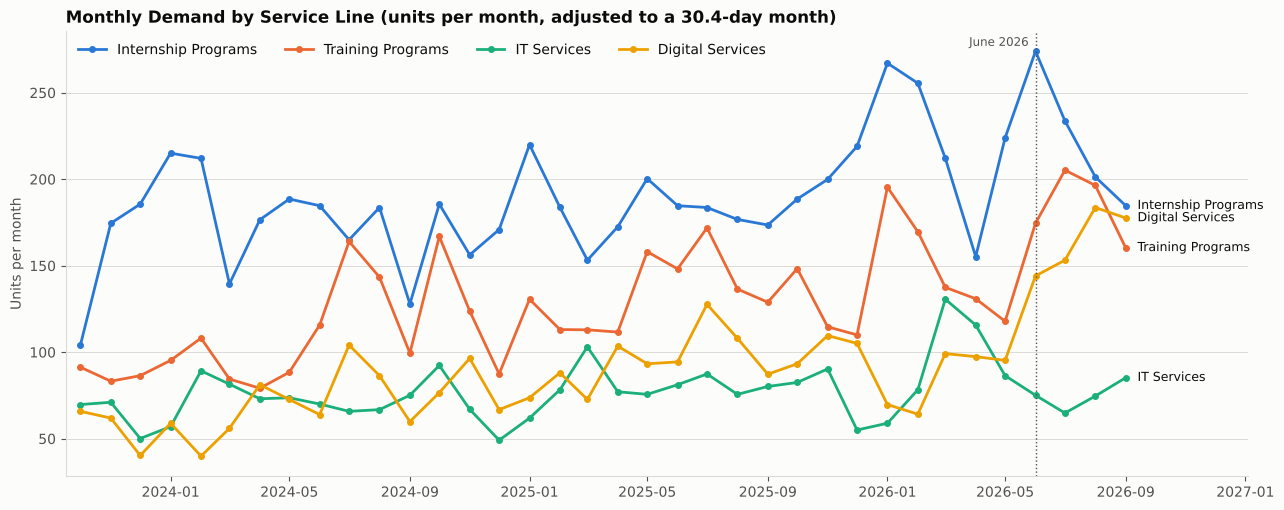

In [10]:
monthly_units = monthly.pivot(index="month", columns="service_line", values="demand_units")[LINES]
monthly_units = monthly_units.div(monthly.groupby("month")["days"].first() / 30.44, axis=0)    # units per 30.44 days, so months of different length compare fairly

fig, ax = plt.subplots(figsize=(13, 5.2))
for line in LINES:
    ax.plot(monthly_units.index, monthly_units[line], color=COLORS[line], linewidth=2, marker="o", markersize=4, label=line)
    ax.text(monthly_units.index[-1] + pd.Timedelta(days=12), monthly_units[line].iloc[-1], line, color=INK, fontsize=9, va="center")
ax.axvline(pd.Timestamp("2026-06-01"), color=INK_SOFT, linestyle=":", linewidth=1)
ax.text(pd.Timestamp("2026-05-25"), ax.get_ylim()[1] * 0.97, "June 2026", ha="right", fontsize=8.5, color=INK_SOFT)
ax.set_title("Monthly Demand by Service Line (units per month, adjusted to a 30.4-day month)")
ax.set_ylabel("Units per month")
ax.set_xlim(monthly_units.index[0] - pd.Timedelta(days=15), monthly_units.index[-1] + pd.Timedelta(days=125))
ax.legend(loc="upper left", frameon=False, ncol=4)
clean_axes(ax)
plt.tight_layout()
plt.show()

**Observation:** Three years of demand show a clear growth trend and a repeating yearly pattern. The total demand grew from 4,938 units in the first year to 5,766 and then 6,860 (+38.9% in two years), and the lines grew at very different speeds: Digital Services +75.6%, Training Programs +49.7%, Internship Programs +26.8%, and IT Services +18.1%. The yearly pattern repeats in each line: Internship Programs peak in January (219, 224, and 272 units in the three Januaries), Training Programs in July (167 and 175, and 209 in 2026), IT Services in March (83, 105, and 133), and Digital Services in July and August. The change that was built into the last months is visible: from June 2026, Digital Services jump to 142, 156, 187, and 175 units a month, 57.5% above the same four months of 2025 (the year before, the same comparison was +32.6%), while IT Services fall 7.7% below the same months of 2025 (after +16.9% the year before). A forecast that only continues the old trend would miss both changes, which is the point of the last forecasting days.

**Weekly demand by service line**

Weeks smooth the day-to-day noise but still show campaigns and holidays. The darker line is the
13-week (one quarter) moving average, which follows the level without the short bumps.

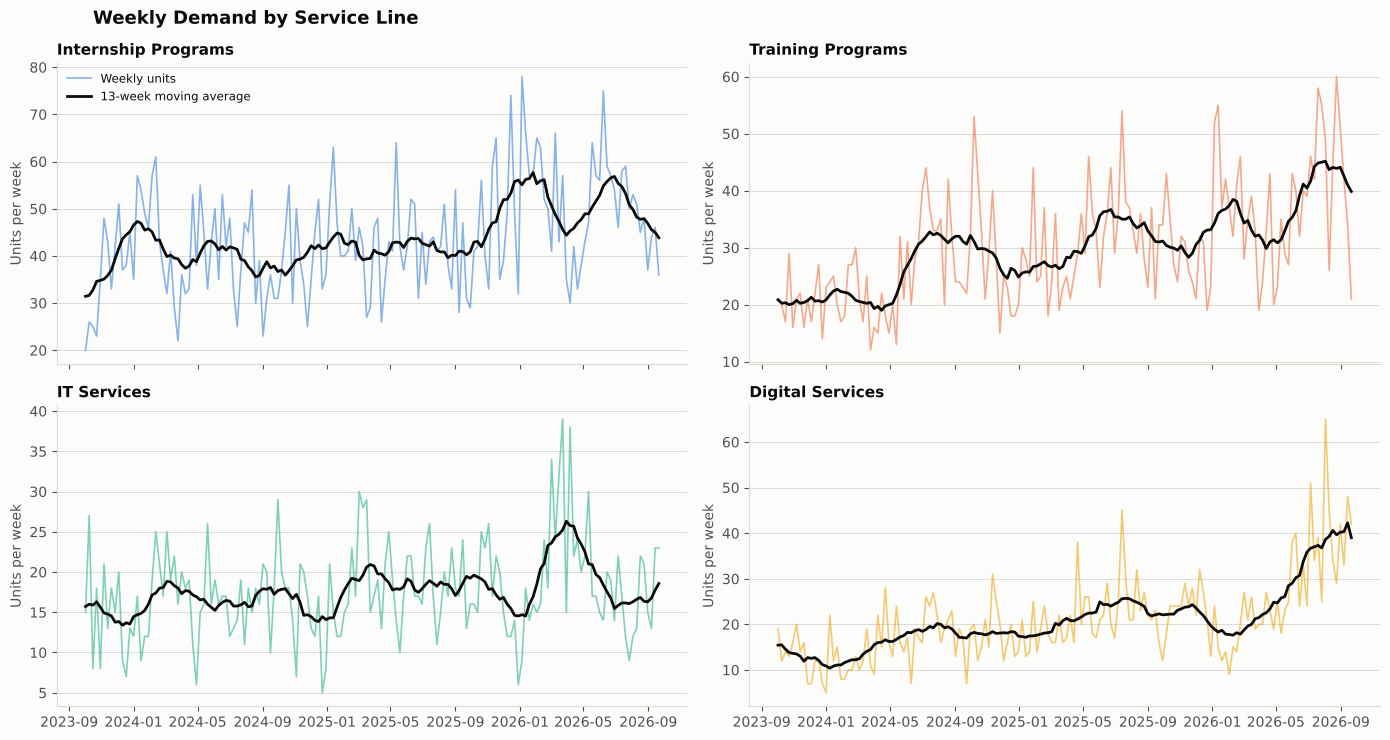

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True)
weekly_units = weekly.pivot(index="week_start", columns="service_line", values="demand_units")[LINES]
for ax, line in zip(axes.ravel(), LINES):
    ax.plot(weekly_units.index, weekly_units[line], color=COLORS[line], alpha=0.55, linewidth=1.2, label="Weekly units")
    ax.plot(weekly_units.index, weekly_units[line].rolling(13, center=True, min_periods=7).mean(), color=INK, linewidth=2, label="13-week moving average")
    ax.set_title(line, fontsize=11)
    ax.set_ylabel("Units per week")
    clean_axes(ax)
axes[0, 0].legend(loc="upper left", frameon=False, fontsize=8.5)
fig.suptitle("Weekly Demand by Service Line", x=0.07, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Observation:** Weekly demand is much noisier than the monthly chart suggests: a line can move by 10 or more units from one week to the next, and the total demand of all lines ranged from 61 to 179 units per week (median 111). The 13-week moving average removes this noise and shows the structure: a steady rise in Digital Services, a rise with yearly waves in Training Programs and Internship Programs, and a flat IT Services line with a high stretch in the spring of 2026 (the March season combined with a campaign) followed by the slowdown. The total weekly demand averaged 83.8 units in the first 13 weeks and 147.8 in the last 13 weeks. Because a single week can differ so much from the level, a forecast should be judged over several weeks, and the planning decisions should use ranges and not single numbers.

**The weekly pattern: demand by weekday**

Each point is the average demand of that weekday divided by the average demand of all days, so 1.0 is
an average day.

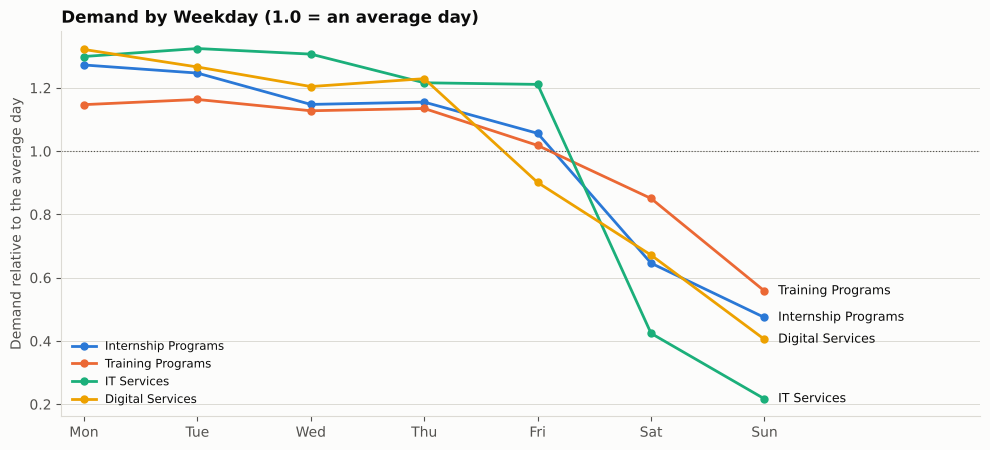

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
service_line,,,,,,,
Internship Programs,1.27,1.25,1.15,1.16,1.06,0.65,0.47
Training Programs,1.15,1.16,1.13,1.14,1.02,0.85,0.56
IT Services,1.30,1.32,1.31,1.22,1.21,0.42,0.22
Digital Services,1.32,1.27,1.20,1.23,0.90,0.67,0.40


In [12]:
weekday_index = clean.assign(weekday=clean["date"].dt.dayofweek).groupby(["service_line", "weekday"])["demand_units"].mean().unstack()
weekday_index = weekday_index.div(clean.groupby("service_line")["demand_units"].mean(), axis=0).loc[LINES]
weekday_index.columns = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(10, 4.6))
for line in LINES:
    ax.plot(weekday_index.columns, weekday_index.loc[line], color=COLORS[line], linewidth=2, marker="o", markersize=5, label=line)
    ax.text(6.12, weekday_index.loc[line].iloc[-1], line, fontsize=9, va="center")
ax.axhline(1, color=INK_SOFT, linewidth=0.8, linestyle=":")
ax.set_xlim(-0.2, 7.9)
ax.set_ylabel("Demand relative to the average day")
ax.set_title("Demand by Weekday (1.0 = an average day)")
ax.legend(loc="lower left", frameon=False, fontsize=8.5)
clean_axes(ax)
plt.tight_layout()
plt.show()
weekday_index.round(2)

**Observation:** Demand follows a weekly rhythm in every line: Monday to Thursday are above an average day (1.1 to 1.35) and the weekend is far below. IT Services, which depend on business clients, fall the most (0.42 on Saturday and 0.23 on Sunday, so weekends hold only 9.1% of the demand), while Training Programs fall the least (0.86 on Saturday, 20.1% of the demand on weekends), because the simulation assumes that students also enroll at the weekend. The Friday value of Digital Services (0.89) is lower than the other lines, which is partly noise in a line with only 3 units on a typical day. This weekly pattern is why the filled values use the same weekday and why the forecasting models need the day of the week.

**Units and revenue are not the same thing**

The service lines that bring most of the demand are not the ones that bring most of the revenue,
so the forecasting has to be read together with the value of each line.

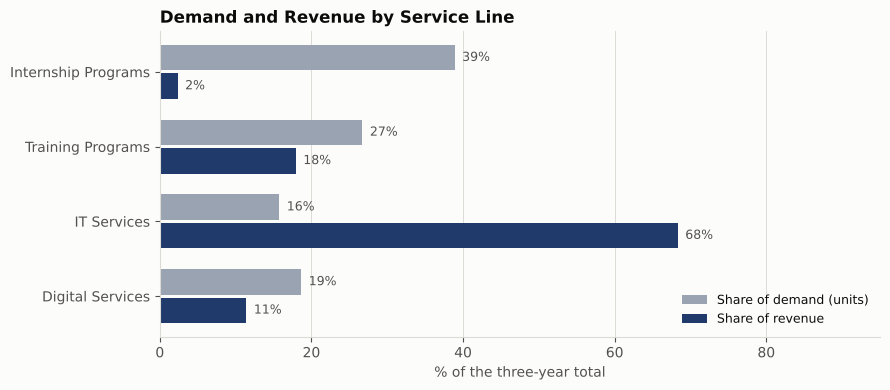

,share_of_units_pct,share_of_revenue_pct,revenue_per_unit_inr
service_line,,,
Internship Programs,38.9,2.3,1196.9
Training Programs,26.7,17.9,13335.4
IT Services,15.8,68.3,86157.1
Digital Services,18.6,11.4,12159.3


In [13]:
mix = pd.DataFrame({"share_of_units_pct": clean.groupby("service_line")["demand_units"].sum() / total_units * 100,
                    "share_of_revenue_pct": clean.groupby("service_line")["revenue_inr"].sum() / total_revenue * 100,
                    "revenue_per_unit_inr": clean.groupby("service_line")["revenue_inr"].sum() / clean.groupby("service_line")["demand_units"].sum()}).loc[LINES]

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(LINES))
ax.barh(y - 0.19, mix["share_of_units_pct"], height=0.34, color="#9aa3b2", label="Share of demand (units)")
ax.barh(y + 0.19, mix["share_of_revenue_pct"], height=0.34, color="#1f3a6b", label="Share of revenue")
for yi, a, b in zip(y, mix["share_of_units_pct"], mix["share_of_revenue_pct"]):
    ax.text(a + 1, yi - 0.19, f"{a:.0f}%", va="center", fontsize=9, color=INK_SOFT)
    ax.text(b + 1, yi + 0.19, f"{b:.0f}%", va="center", fontsize=9, color=INK_SOFT)
ax.set_yticks(y)
ax.set_yticklabels(LINES)
ax.invert_yaxis()
ax.set_xlim(0, 95)
ax.set_xlabel("% of the three-year total")
ax.set_title("Demand and Revenue by Service Line")
ax.legend(loc="lower right", frameon=False, fontsize=9)
clean_axes(ax, "x")
plt.tight_layout()
plt.show()
mix.round(1)

**Observation:** Demand and revenue tell different stories. Internship Programs are 39% of the units but only 2.3% of the revenue (INR 1,200 per unit), while IT Services are 15.8% of the units and 68.4% of the revenue (INR 86,702 per unit). Training Programs bring 17.9% of the revenue and Digital Services 11.4%. The total revenue over the three years is INR 349.0 million. This matters for planning: a forecast error of 10 units is almost harmless for Internship Programs and expensive for IT Services, so the forecasts have to be read with the value of each line, and the accuracy of the IT Services forecast deserves the most attention.

**Consistency check with SQL**

The monthly totals by service line are repeated in SQL with `sqlite3` to confirm that they match pandas.

In [14]:
connection = sqlite3.connect(":memory:")
clean_out.to_sql("demand_daily", connection, index=False)
sql_monthly = pd.read_sql_query("""
    SELECT substr(date, 1, 7) AS month, service_line, SUM(demand_units) AS demand_units
    FROM demand_daily GROUP BY month, service_line ORDER BY month, service_line""", connection)
connection.close()

pandas_monthly = monthly.assign(month=monthly["month"].dt.strftime("%Y-%m"))[["month", "service_line", "demand_units"]].sort_values(["month", "service_line"]).reset_index(drop=True)
print("SQL monthly totals match pandas:", sql_monthly.equals(pandas_monthly.astype({"demand_units": sql_monthly["demand_units"].dtype})), "| rows:", len(sql_monthly))

SQL monthly totals match pandas: True | rows: 144


## Outcome

By the end of this task, I had a reproducible simulated demand history, a time-series preprocessing pipeline that restored it, and the first look at the demand that prepares Day 46. The history covers 36 months (1,096 days) and four service lines, with 17,564 units of demand and INR 349.0 million of revenue. The pipeline turned a messy export of 4,404 rows into a complete calendar of 4,384 rows, was checked against the original (99.98% of the undamaged rows unchanged, 157 filled values with an average error of 1.76 units against 2.24 for a plain average), and saved the cleaned daily, weekly, and monthly tables in `datasets/veda_demand/`. The charts show growth that differs by line (from +18% for IT Services to +76% for Digital Services over two years), a yearly pattern with a different peak month for each line, a strong weekday pattern, and a change in the last months (Digital Services up and IT Services down). Demand and revenue are very unequal: Internship Programs are 39% of the units and 2% of the revenue, while IT Services are 16% of the units and 68% of the revenue. Because the data is simulated, these findings reflect the assumptions I built into it, so they practice the analysis workflow and do not describe the real company. The main lesson was that time-series cleaning needs time-series logic: every day must exist, a filled value should respect the weekday pattern, and an outage or a spike has to be judged against its neighbors and against a second source (here the revenue), because the same raw value can be a real event or an error.